In [2]:
import stim
import numpy as np

In [23]:
Error_rate = 0.001
Rep_number = 2
Code_size = 3


def create_memory_circuit_my(Code_size ,Rep_number ,Error_rate):
    N_qubits = Code_size * 2 - 1
    circuit_descr_pr = ""
    str_1 = ""
    circuit_descr_pr = circuit_descr_pr + str_1
    
    def Create_R(qubits):
        str_1 = "R "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    def Create_CX(qubits):
        str_1 = f"CX "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    
    def Create_Xerror(qubits, error_rate):
        str_1 = f"X_ERROR({error_rate}) "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    def Create_Depolarize1(qubits, error_rate):
        str_1 = f"DEPOLARIZE1({error_rate}) "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    def Create_Depolarize2(qubits, error_rate):
        str_1 = f"DEPOLARIZE2({error_rate}) "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    def Create_Measurements(qubits):
        str_1 = "M "
        for q in qubits:
            str_1 = str_1 + f"{q} "
        str_1 = str_1 + "\n"
        return str_1
    
    def Create_RepeatBlock(n_rep, block):
        str_1 = f"REPEAT {n_rep} {{ \n" + block + f"}} \n"
        return str_1
    
    def Create_SHIFT_COORDS(n_q, n_t):
        str_1 = f"SHIFT_COORDS({n_q},{n_t}) \n"
        return str_1
    
    def Create_DETECTOR(n_q, n_t, meas_time_list):
        str_1 = f"DETECTOR({n_q},{n_t}) "
        for t_sh in meas_time_list:
            str_1 = str_1 + f"rec[-{t_sh}] "
        str_1 = str_1 + "\n"
        return str_1
        
    
    #Reset
    qubits = np.array(range(N_qubits))
    circuit_descr_pr = circuit_descr_pr + Create_R(qubits)
    
    #First layer of X error
    qubits = np.array(range(N_qubits))
    circuit_descr_pr = circuit_descr_pr + Create_Xerror(qubits, Error_rate)
    
    #first CX gates line
    qubits = np.array(range(N_qubits - 1))
    circuit_descr_pr = circuit_descr_pr + Create_CX(qubits)
    
    #Layer of depolarizers
    qubits = np.array(range(N_qubits - 1))
    circuit_descr_pr = circuit_descr_pr + Create_Depolarize2(qubits, Error_rate)
    circuit_descr_pr = circuit_descr_pr + Create_Depolarize1([N_qubits-1], Error_rate)
    
    #Second line of CX gates
    ng = int((N_qubits - 1) / 2)
    qubits = []
    for i in range(ng):
        qubits.append((i + 1) * 2)
        qubits.append(i * 2 + 1)
    circuit_descr_pr = circuit_descr_pr + Create_CX(qubits)
    
    #Layer of depolarizers
    circuit_descr_pr = circuit_descr_pr + Create_Depolarize2(qubits, Error_rate)
    circuit_descr_pr = circuit_descr_pr + Create_Depolarize1([0], Error_rate)
    
    #Add measurement errors
    qubits = np.array(range(1,N_qubits,2))
    circuit_descr_pr = circuit_descr_pr + Create_Xerror(qubits, Error_rate)
    
    #Add measurements
    qubits = np.array(range(1,N_qubits,2))
    circuit_descr_pr = circuit_descr_pr + Create_Measurements(qubits)
    
    #Layer of depolarizers
    qubits = np.array(range(0,N_qubits,2))
    circuit_descr_pr = circuit_descr_pr + Create_Depolarize1(qubits, Error_rate)
    
    #Add detectors
    det_list = np.array(range(1,N_qubits,2))
    for i_det in range(len(det_list)):
        m_t = [len(det_list) - i_det]
        circuit_descr_pr = circuit_descr_pr + Create_DETECTOR(2*i_det+1, 0, m_t)
    
    
    
    
    
    
    #Creating the block for repetition
    Rep_block = ""
    #Reset
    qubits = np.array(range(1,N_qubits,2))
    Rep_block = Rep_block + Create_R(qubits)
    
    #First layer of X error
    Rep_block = Rep_block + Create_Xerror(qubits, Error_rate)
    
    #Layer of depolarizer errors
    qubits = np.array(range(0, N_qubits, 2))
    Rep_block = Rep_block + Create_Depolarize1(qubits, Error_rate)
    
    #first CX gates line
    qubits = np.array(range(N_qubits - 1))
    Rep_block = Rep_block + Create_CX(qubits)
    
    #Layer of depolarizers
    qubits = np.array(range(N_qubits - 1))
    Rep_block = Rep_block + Create_Depolarize2(qubits, Error_rate)
    Rep_block = Rep_block + Create_Depolarize1([N_qubits-1], Error_rate)
    
    #Second line of CX gates
    ng = int((N_qubits - 1) / 2)
    qubits = []
    for i in range(ng):
        qubits.append((i + 1) * 2)
        qubits.append(i * 2 + 1)
    Rep_block = Rep_block + Create_CX(qubits)
    
    #Layer of depolarizers
    Rep_block = Rep_block + Create_Depolarize2(qubits, Error_rate)
    Rep_block = Rep_block + Create_Depolarize1([0], Error_rate)
    
    #Add measurement errors
    qubits = np.array(range(1,N_qubits,2))
    Rep_block = Rep_block + Create_Xerror(qubits, Error_rate)
    
    #Add measurements
    qubits = np.array(range(1,N_qubits,2))
    Rep_block = Rep_block + Create_Measurements(qubits)
    
    #Layer of depolarizers
    qubits = np.array(range(0,N_qubits,2))
    Rep_block = Rep_block + Create_Depolarize1(qubits, Error_rate)
    
    #Add coordinate shift
    Rep_block = Rep_block + Create_SHIFT_COORDS(0, 1)
    
    #Add detectors
    det_list = np.array(range(1,N_qubits,2))
    for i_det in range(len(det_list)):
        m_t = [len(det_list) - i_det, 2*len(det_list) - i_det  ]
        Rep_block = Rep_block + Create_DETECTOR(2*i_det+1, 0, m_t)
    
    circuit_descr_pr = circuit_descr_pr + Create_RepeatBlock(Rep_number - 1, Rep_block)
    
    
    
    
    
    
    #Creating the last block concluding the circuit
    Rep_block = ""
    #Reset
    qubits = np.array(range(1,N_qubits,2))
    str_1 = Create_R(qubits)
    Rep_block = Rep_block + str_1
    
    #First layer of X error
    str_1 = Create_Xerror(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    
    #Layer of depolarizer errors
    qubits = np.array(range(0, N_qubits, 2))
    str_1 = Create_Depolarize1(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    
    #first CX gates line
    qubits = np.array(range(N_qubits - 1))
    str_1 = Create_CX(qubits)
    Rep_block = Rep_block + str_1
    
    #Layer of depolarizers
    qubits = np.array(range(N_qubits - 1))
    str_1 = Create_Depolarize2(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    str_1 = Create_Depolarize1([N_qubits-1], Error_rate)
    Rep_block = Rep_block + str_1
    
    #Second line of CX gates
    ng = int((N_qubits - 1) / 2)
    qubits = []
    for i in range(ng):
        qubits.append((i + 1) * 2)
        qubits.append(i * 2 + 1)
    str_1 = Create_CX(qubits)
    Rep_block = Rep_block + str_1
    
    #Layer of depolarizers
    str_1 = Create_Depolarize2(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    str_1 = Create_Depolarize1([0], Error_rate)
    Rep_block = Rep_block + str_1
    
    #Add measurement errors
    qubits = np.array(range(1,N_qubits,2))
    str_1 = Create_Xerror(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    
    #Add measurements
    qubits = np.array(range(1,N_qubits,2))
    str_1 = Create_Measurements(qubits)
    Rep_block = Rep_block + str_1
    qubits = np.array(range(0,N_qubits,2))
    str_1 = Create_Measurements(qubits)
    Rep_block = Rep_block + str_1
    
    #Layer of depolarizers
    qubits = np.array(range(0,N_qubits,2))
    str_1 = Create_Depolarize1(qubits, Error_rate)
    Rep_block = Rep_block + str_1
    
    #Add coordinate shift
    str_1 = Create_SHIFT_COORDS(0, 1)
    Rep_block = Rep_block + str_1
    
    #Add detectors
    det_list = np.array(range(1,N_qubits,2))
    for i_det in range(len(det_list)):
        m_t = [len(det_list) - (i_det) + Code_size, 2 * len(det_list) - (i_det) + Code_size]
        str_1 = Create_DETECTOR(2*i_det+1, 0, m_t)
        Rep_block = Rep_block + str_1
    
    for i_det in range(Code_size - 1):
        m_t = [i_det + 1, i_det + 2, i_det + 1 + Code_size]
        str_1 = Create_DETECTOR(Code_size - (2 * i_det ), 0, m_t)
        Rep_block = Rep_block + str_1
        
    circuit_descr_pr = circuit_descr_pr + Rep_block
    circuit_descr_pr = circuit_descr_pr + "OBSERVABLE_INCLUDE(0) rec[-1]"
    circ = stim.Circuit(circuit_descr_pr)
    return circ

#print(circuit_descr_pr)

#c_pr = stim.Circuit(circuit_descr_pr)
#dem = c_pr.detector_error_model()

import pymatching



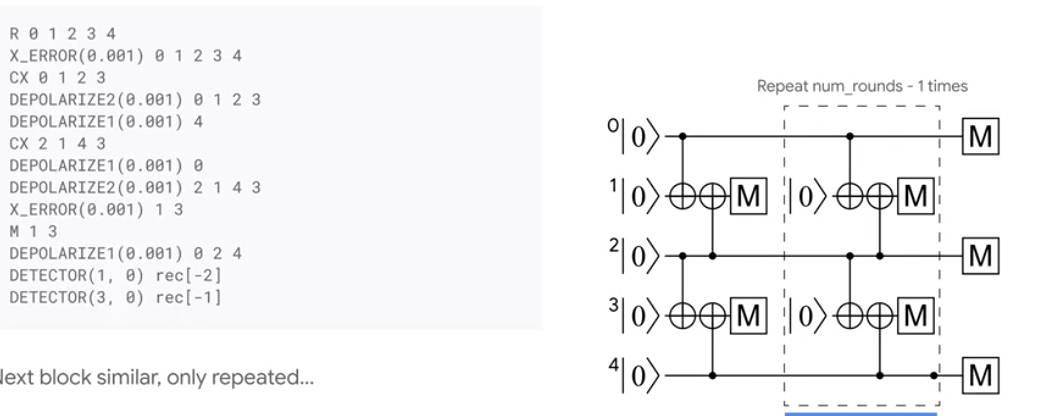

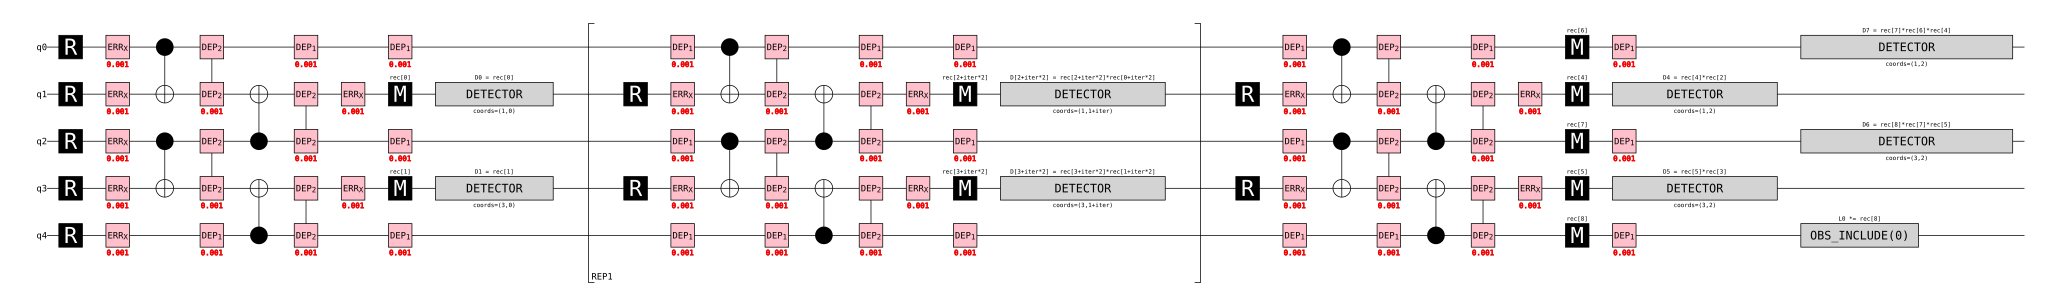

In [24]:
circuit = create_memory_circuit(3,2,0.001)
circuit.diagram('timeline-svg')

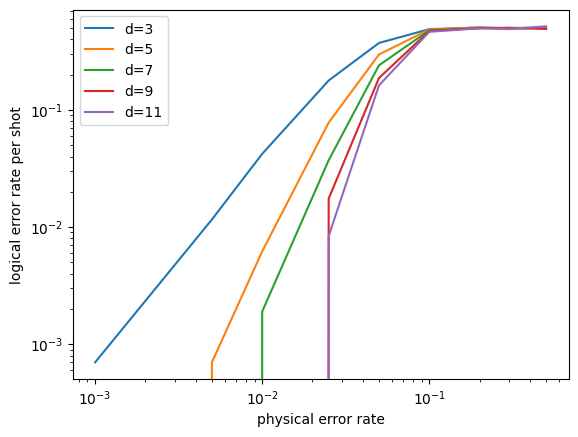

In [25]:
import matplotlib.pyplot as plt

def count_logical_errors(circuit: stim.Circuit, num_shots: int) -> int:
    # Sample the circuit.
    sampler = circuit.compile_detector_sampler()
    detection_events, observable_flips = sampler.sample(num_shots, separate_observables=True)

    # Configure a decoder using the circuit.
    detector_error_model = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(detector_error_model)

    # Run the decoder.
    predictions = matcher.decode_batch(detection_events)

    # Count the mistakes.
    num_errors = 0
    for shot in range(num_shots):
        actual_for_shot = observable_flips[shot]
        predicted_for_shot = predictions[shot]
        if not np.array_equal(actual_for_shot, predicted_for_shot):
            num_errors += 1
    return num_errors

num_shots = 10000
for d in [3, 5, 7, 9, 11]:
    xs = []
    ys = []
    for noise in [0.001, 0.005, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5]:
        #print(noise)
        circuit = create_memory_circuit_my(d,8,noise)
        num_errors_sampled = count_logical_errors(circuit, num_shots)
        xs.append(noise)
        ys.append(num_errors_sampled / num_shots)
    plt.plot(xs, ys, label="d=" + str(d))
plt.loglog()
plt.xlabel("physical error rate")
plt.ylabel("logical error rate per shot")
plt.legend()
plt.show()

In [26]:
#pip install pymatching

In [28]:
#parameters section
Error_rate = 0.001
Rep_number = 8
Code_size = 3
N_qubits = Code_size * 2 - 1

circuit_descr = f"""
    R 0 1 2 3 4
    X_ERROR(0.001) 0 1 2 3 4  
    CX 0 1 2 3 
    DEPOLARIZE2(0.001) 0 1 2 3 
    DEPOLARIZE1(0.001) 4 
    CX 2 1 4 3 
    DEPOLARIZE1(0.001) 0  
    DEPOLARIZE2(0.001) 2 1 4 3 
    X_ERROR(0.001) 1 3 
    M 1 3
    DEPOLARIZE1(0.001) 0 2 4  
    DETECTOR(1, 0) rec[-2]
    DETECTOR(3, 0) rec[-1]
    
    REPEAT 7 {
        R 1 3    
        X_ERROR(0.001) 1 3  
        DEPOLARIZE1(0.001) 0 2 4 
        CX 0 1 2 3 
        DEPOLARIZE2(0.001) 0 1 2 3 
        DEPOLARIZE1(0.001) 4 
        CX 2 1 4 3 
        DEPOLARIZE1(0.001) 0  
        DEPOLARIZE2(0.001) 2 1 4 3 
        X_ERROR(0.001) 1 3 
        M 1 3
        DEPOLARIZE1(0.001) 0 2 4  
        SHIFT_COORDS(0, 1)
        DETECTOR(1, 0) rec[-2] rec[-4]
        DETECTOR(3, 0) rec[-1] rec[-3]
    }
    R 1 3    
    X_ERROR(0.001) 1 3  
    DEPOLARIZE1(0.001) 0 2 4 
    CX 0 1 2 3 
    DEPOLARIZE2(0.001) 0 1 2 3 
    DEPOLARIZE1(0.001) 4 
    CX 2 1 4 3 
    DEPOLARIZE1(0.001) 0  
    DEPOLARIZE2(0.001) 2 1 4 3 
    X_ERROR(0.001) 1 3 
    M 1 3 0 2 4
    DEPOLARIZE1(0.001) 0 2 4  
    SHIFT_COORDS(0, 1)
    DETECTOR(1, 0) rec[-5] rec[-7]
    DETECTOR(3, 0) rec[-4] rec[-6]
    DETECTOR(1, 0) rec[-2] rec[-3] rec[-5]
    DETECTOR(3, 0) rec[-1] rec[-2] rec[-4]

    OBSERVABLE_INCLUDE(0) rec[-1]
    """

c = stim.Circuit(circuit_descr)

In [29]:
print(circuit_descr)


    R 0 1 2 3 4
    X_ERROR(0.001) 0 1 2 3 4 
 
    CX 0 1 2 3

    DEPOLARIZE2(0.001) 0 1 2 3

    DEPOLARIZE1(0.001) 4

    CX 2 1 4 3

    DEPOLARIZE1(0.001) 0 

    DEPOLARIZE2(0.001) 2 1 4 3

    X_ERROR(0.001) 1 3

    M 1 3
    DEPOLARIZE1(0.001) 0 2 4 

    DETECTOR(1, 0) rec[-2]
    DETECTOR(3, 0) rec[-1]

    REPEAT 7 {
        R 1 3 
  
        X_ERROR(0.001) 1 3 

        DEPOLARIZE1(0.001) 0 2 4

        CX 0 1 2 3

        DEPOLARIZE2(0.001) 0 1 2 3

        DEPOLARIZE1(0.001) 4

        CX 2 1 4 3

        DEPOLARIZE1(0.001) 0 

        DEPOLARIZE2(0.001) 2 1 4 3

        X_ERROR(0.001) 1 3

        M 1 3
        DEPOLARIZE1(0.001) 0 2 4 

        SHIFT_COORDS(0, 1)
        DETECTOR(1, 0) rec[-2] rec[-4]
        DETECTOR(3, 0) rec[-1] rec[-3]
    }
    R 1 3 
  
    X_ERROR(0.001) 1 3 

    DEPOLARIZE1(0.001) 0 2 4

    CX 0 1 2 3

    DEPOLARIZE2(0.001) 0 1 2 3

    DEPOLARIZE1(0.001) 4

    CX 2 1 4 3

    DEPOLARIZE1(0.001) 0 

    DEPOLARIZE2(0.001) 2 1 4 3

    X_E

In [58]:
res = c.compile_sampler().sample(10)
res_pr = c_pr.compile_sampler().sample(10)
print(res)
print(res_pr)


[[False False False False False False False False False False False False
  False False False False False False False False False]
 [False False False False False False False False  True False  True False
   True False  True False  True False  True False False]
 [False False False False False False False False False False False False
  False False False False False False False False False]
 [False False False False False False False False False False False False
  False False False False False False False False False]
 [False False False False False False False False False False False False
  False False False False False False False False False]
 [False False False False False False False False False False False False
  False False  True False  True False  True False False]
 [False False False False False False False False False False False False
  False False False False False False False False False]
 [False False False False False False False False False False False  True
  False F

In [38]:
print(c.diagram("timeline-text"))

                                                                                                                                           /REP 4                                                                                                                                                                              \
q0: -R-X_ERROR(0.001)-@-DEPOLARIZE2(0.001)-DEPOLARIZE1(0.001)-----------------------------------DEPOLARIZE1(0.001)-------------------------|--------DEPOLARIZE1(0.001)-@-DEPOLARIZE2(0.001)-DEPOLARIZE1(0.001)-----------------------------------DEPOLARIZE1(0.001)------------------------------------------------------------|---DEPOLARIZE1(0.001)-@-DEPOLARIZE2(0.001)-DEPOLARIZE1(0.001)-----------------------------------M:rec[12]-DEPOLARIZE1(0.001)---------------DETECTOR(1,5):D12=rec[13]*rec[12]*rec[10]-
                      | |                                                                                                                  |                           | |       

In [17]:
res

array([[False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False],
       [False, False]])